# Lab: um filtro de spam com random forests

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/random-forest/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar

**Preveja.** Que palavras você espera ver com muito mais frequência no spam do que no e-mail legítimo? Alguma palavra poderia indicar "legítimo" só por causa de quem coletou os dados?

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)
spam = fetch_openml(data_id=44, as_frame=True)       # Spambase (UCI): 4.601 e-mails
X = spam.data                                        # 57 atributos numéricos
y = (spam.target == '1').astype(int)                 # 1 = spam, 0 = legítimo
print(X.shape)
print(y.value_counts())
tokens = ['word_freq_free', 'word_freq_remove', 'char_freq_%24', 'word_freq_george', 'word_freq_hp']
print(X[tokens].gt(0).groupby(y).mean().round(3))    # fração de e-mails que contêm cada token

(4601, 57)
class
0    2788
1    1813
Name: count, dtype: int64
       word_freq_free  word_freq_remove  char_freq_%24  word_freq_george  word_freq_hp
class                                                                                 
0               0.090             0.015          0.104             0.277         0.373
1               0.546             0.421          0.612             0.004         0.028


**Resposta.** No spam, `free` (54,6% dos spams contra 9,0% dos legítimos), `remove` (42,1% contra 1,5%) e o `$` (61,2% contra 10,4%). Sim: `george` (27,7% contra 0,4%) e `hp` (37,3% contra 2,8%) indicam "legítimo" só porque os e-mails legítimos vieram da caixa de um George, funcionário da HP Labs.

## Passo 2 — trancar o conjunto de teste

**Preveja.** Com 921 e-mails no teste, quanto vale um único e-mail em pontos de acurácia?

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(f"spam share: train {y_train.mean():.3f} · test {y_test.mean():.3f}")

(3680, 57) (921, 57)
spam share: train 0.394 · test 0.394


**Resposta.** Um e-mail em 921 vale 1/921 ≈ 0,11 ponto de acurácia, então diferenças de um décimo de ponto no teste correspondem a um único e-mail.

## Passo 3 — um baseline e os folds que todos compartilham

**Preveja.** Se 39,4% dos e-mails são spam, quanto acerta um modelo que chama tudo de legítimo? E qual é a ROC AUC dele?

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = {}                                           # as 5 notas por fold de cada modelo, para o passo 5


def evaluate(name, model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc'])
    folds[name] = r
    print(f"{name:14s} accuracy {r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f} · "
          f"ROC AUC {r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}")


evaluate('dummy', DummyClassifier(strategy='most_frequent'))

dummy          accuracy 0.606 ± 0.000 · ROC AUC 0.500 ± 0.000


**Resposta.** Chamando tudo de legítimo, acerta 1 − 0,394 = 60,6% (a saída mostra 0,606). A ROC AUC é 0,500: com a mesma nota para todos os e-mails, o modelo não ordena nada.

## Passo 4 — uma árvore, bagging, random forest, Extra-Trees

**Preveja.** Entre uma árvore e os três ensembles, em qual métrica a diferença vai ser maior, acurácia ou ROC AUC? Por quê?

In [4]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

evaluate('one tree', DecisionTreeClassifier(random_state=0))
evaluate('bagging', RandomForestClassifier(n_estimators=200, max_features=None,   # todos os 57 atributos
                                           random_state=0, n_jobs=-1))
evaluate('random forest', RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1))
evaluate('extra-trees', ExtraTreesClassifier(n_estimators=200, random_state=0, n_jobs=-1))

one tree       accuracy 0.916 ± 0.008 · ROC AUC 0.913 ± 0.007


bagging        accuracy 0.940 ± 0.006 · ROC AUC 0.978 ± 0.005


random forest  accuracy 0.953 ± 0.006 · ROC AUC 0.986 ± 0.004


extra-trees    accuracy 0.957 ± 0.008 · ROC AUC 0.987 ± 0.004


**Resposta.** Na ROC AUC: da árvore para a floresta, a acurácia sobe 0,037 (0,916 → 0,953) e a AUC sobe 0,073 (0,913 → 0,986). Uma árvore crescida até o fim tem folhas puras e dá probabilidades quase só 0 ou 1, que ordenam mal; a média de 200 votos produz notas graduadas, e é isso que a AUC mede.

**Simulação: a floresta é melhor que as próprias árvores?** No primeiro fold do `cv`, ajuste uma floresta de 200 árvores e meça a acurácia de validação de cada árvore sozinha: a média, a melhor e a pior. Compare com o voto da floresta e com uma única árvore crescida em todas as linhas do fold. Alguma árvore da floresta chega ao voto?

In [5]:
tr, va = next(cv.split(X_train, y_train))                  # o primeiro fold
Xf, yf = X_train.iloc[tr], y_train.iloc[tr]
Xv, yv = X_train.iloc[va], y_train.iloc[va].to_numpy()

forest = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1).fit(Xf, yf)
tree_acc = np.array([np.mean(t.predict(Xv.to_numpy()) == yv) for t in forest.estimators_])
forest_acc = forest.score(Xv, yv)
single_acc = DecisionTreeClassifier(random_state=0).fit(Xf, yf).score(Xv, yv)

print(f"200 trees alone: mean {tree_acc.mean():.3f} · best {tree_acc.max():.3f} · worst {tree_acc.min():.3f}")
print(f"forest vote: {forest_acc:.3f} · one tree on all rows of the fold: {single_acc:.3f}")
print(f"trees that reach the vote: {(tree_acc >= forest_acc).sum()} of 200")

200 trees alone: mean 0.900 · best 0.935 · worst 0.861
forest vote: 0.961 · one tree on all rows of the fold: 0.928
trees that reach the vote: 0 of 200


**Leitura.** As 200 árvores sozinhas acertam em média 0,900 (melhor 0,935, pior 0,861), e o voto da floresta chega a 0,961. Nenhuma das 200 árvores alcança o voto, e mesmo a árvore crescida em todas as linhas do fold fica em 0,928. A floresta é melhor que qualquer uma de suas árvores, porque os erros delas caem em e-mails diferentes.

## Passo 5 — diferenças pareadas, fold a fold

**Preveja.** A floresta está 1,3 ponto de acurácia à frente do bagging, com desvios entre folds de cerca de 0,006. Isso basta para declarar vitória? Que comparação resolve a dúvida?

In [6]:
for a, b in [('random forest', 'one tree'), ('random forest', 'bagging'), ('extra-trees', 'random forest')]:
    for metric in ['accuracy', 'roc_auc']:
        d = folds[a]['test_' + metric] - folds[b]['test_' + metric]
        print(f"{a} - {b:14s} {metric:8s} {d.round(3)}  ->  {d.mean():+.3f} ± {d.std():.3f}")

random forest - one tree       accuracy [0.033 0.034 0.052 0.031 0.035]  ->  +0.037 ± 0.007
random forest - one tree       roc_auc  [0.065 0.07  0.083 0.076 0.071]  ->  +0.073 ± 0.006
random forest - bagging        accuracy [0.018 0.01  0.01  0.007 0.02 ]  ->  +0.013 ± 0.005
random forest - bagging        roc_auc  [0.006 0.006 0.009 0.01  0.009]  ->  +0.008 ± 0.002
extra-trees - random forest  accuracy [ 0.001  0.005  0.004  0.015 -0.008]  ->  +0.004 ± 0.007
extra-trees - random forest  roc_auc  [ 0.001 -0.001  0.003  0.001  0.001]  ->  +0.001 ± 0.001


**Resposta.** Os desvios de cada modelo sozinhos não bastam, porque os folds são os mesmos e as notas andam juntas; o que resolve é a diferença pareada fold a fold. Ela dá +0,013 ± 0,005 de acurácia para a floresta sobre o bagging, positiva nos cinco folds, então é vitória; já Extra-Trees contra floresta (+0,004 ± 0,007) é empate.

## Passo 6 — out-of-bag: a mesma estimativa, com um ajuste

**Preveja.** Cada árvore deixa de fora cerca de 37% dos e-mails. Uma estimativa feita só com as árvores que não viram cada e-mail vai ficar perto da validação cruzada, bem acima ou bem abaixo dela?

In [7]:
from sklearn.metrics import roc_auc_score

rf = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=0, n_jobs=-1)
rf.fit(X_train, y_train)                             # um ajuste, em todo o X_train
p_oob = rf.oob_decision_function_[:, 1]              # cada e-mail avaliado só por árvores que nunca o viram
print(f"OOB: accuracy {rf.oob_score_:.3f} · ROC AUC {roc_auc_score(y_train, p_oob):.3f}   (1 fit)")
print(f"CV:  accuracy {folds['random forest']['test_accuracy'].mean():.3f} · "
      f"ROC AUC {folds['random forest']['test_roc_auc'].mean():.3f}   (5 fits)")
in_bag = np.array([np.isin(np.arange(len(X_train)), s) for s in rf.estimators_samples_])
n_oob = (~in_bag).sum(axis=0)                        # árvores que NÃO viram cada e-mail
print(f"out-of-bag trees per e-mail: mean {n_oob.mean():.1f} of 200 · min {n_oob.min()} · max {n_oob.max()}")

OOB: accuracy 0.954 · ROC AUC 0.986   (1 fit)
CV:  accuracy 0.953 · ROC AUC 0.986   (5 fits)
out-of-bag trees per e-mail: mean 73.6 of 200 · min 47 · max 100


**Resposta.** Bem perto: OOB dá acurácia 0,954 e ROC AUC 0,986, contra 0,953 e 0,986 na validação cruzada, com um ajuste em vez de cinco. Cada e-mail é avaliado em média por 73,6 das 200 árvores (37%), entre 47 e 100.

## Passo 7 — quantas árvores?

**Preveja.** Passadas algumas dezenas de árvores, o erro OOB continua caindo, estaciona ou volta a subir?

C:\dev\Projetos\Insper\APS-ML\env\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


trees
10     0.0755
25     0.0549
50     0.0503
100    0.0465
200    0.0465
400    0.0457


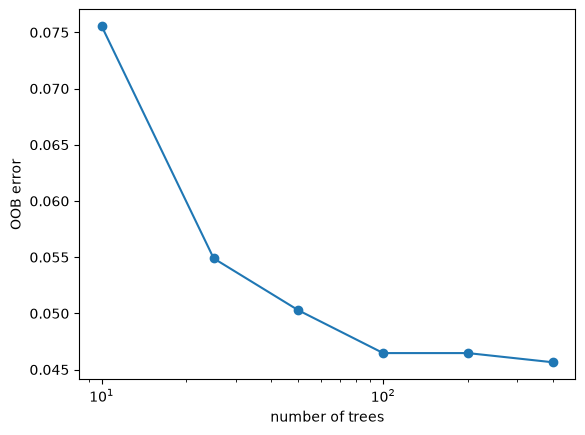

In [8]:
import matplotlib.pyplot as plt

growing = RandomForestClassifier(warm_start=True, oob_score=True, random_state=0, n_jobs=-1)
sizes, oob_error = [10, 25, 50, 100, 200, 400], []
for B in sizes:
    growing.set_params(n_estimators=B).fit(X_train, y_train)   # warm_start: só as árvores novas são crescidas
    oob_error.append(1 - growing.oob_score_)
print(pd.Series(oob_error, index=pd.Index(sizes, name='trees'), name='OOB error').round(4).to_string())
plt.plot(sizes, oob_error, 'o-')
plt.xscale('log'); plt.xlabel('number of trees'); plt.ylabel('OOB error')
plt.show()

**Resposta.** Estaciona: o erro OOB cai de 7,55% com 10 árvores para 4,65% com 100 e fica em 4,57% com 400. Ele não volta a subir, porque mais árvores só reduzem a variância do voto.

**Simulação: árvores rasas, quantas forem.** O passo 7 mostrou o erro OOB estacionar com árvores completas. Repita com árvores de profundidade 3 (`max_depth=3`), para 10, 50, 200 e 400 árvores. Acrescentar árvores leva a floresta rasa até o erro da floresta de árvores completas?

In [9]:
shallow = RandomForestClassifier(max_depth=3, warm_start=True, oob_score=True, random_state=0, n_jobs=-1)
shallow_sizes, shallow_error = [10, 50, 200, 400], []
for B in shallow_sizes:
    shallow.set_params(n_estimators=B).fit(X_train, y_train)
    shallow_error.append(1 - shallow.oob_score_)
print(pd.DataFrame({'depth 3': shallow_error,
                    'full trees': [oob_error[sizes.index(B)] if B in sizes else np.nan for B in shallow_sizes]},
                   index=pd.Index(shallow_sizes, name='trees')).round(4).to_string())

C:\dev\Projetos\Insper\APS-ML\env\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


       depth 3  full trees
trees                     
10      0.1226      0.0755
50      0.0965      0.0503
200     0.0867      0.0465
400     0.0886      0.0457


**Leitura.** Não: a floresta rasa cai de 12,3% de erro com 10 árvores para 8,7% com 200 e estaciona (8,9% com 400), quase o dobro dos 4,6% da floresta de árvores completas. Mais árvores reduzem a variância, mas não o viés de árvores com só 3 perguntas.

**Para fechar a parte fundamental.** Em uma frase cada: (1) por que o voto de 200 árvores acerta mais que a melhor delas? (2) Por que o erro OOB é honesto, se toda árvore foi treinada no `X_train`? (3) Em que situação acrescentar árvores não ajuda nada?

**Resposta.**

1. As árvores erram em e-mails diferentes, porque cada uma vê uma reamostra e sorteia atributos, e a maioria cancela os erros isolados: o voto chegou a 0,961 contra 0,935 da melhor árvore.
2. Cada e-mail é previsto só pelas árvores cuja reamostra não o incluiu (73,6 de 200 em média), então para elas ele é um dado de validação.
3. Depois que o erro estaciona (de 100 para 400 árvores o OOB só foi de 4,65% para 4,57%) ou quando as árvores são viesadas, como as de profundidade 3, que param em cerca de 8,7%.

## Sua vez (fundamental)

Para casa:

1. **Sem as duplicatas.** Refaça os passos 3 a 6 depois de `X = X.drop_duplicates()` (e do `y` correspondente). Quanto caem a acurácia e a ROC AUC de CV? O erro OOB acompanha a queda?
2. **Amostras bootstrap menores.** Use `max_samples=0.2` (cada árvore vê 20% das linhas) e depois `0.5`; compare a ROC AUC de CV e o tempo de ajuste com o padrão. Quantas árvores out-of-bag cada e-mail recebe agora? A estimativa OOB continua perto da CV?
3. **Uma prévia da aula 22.** Acrescente `evaluate('boosting', HistGradientBoostingClassifier(random_state=0))` (de `sklearn.ensemble`) ao passo 4 e calcule sua diferença pareada com a random forest em ROC AUC, como no passo 5. É vitória, derrota ou empate?

## Passo 8 — ajustar `max_features` e `min_samples_leaf`

**Preveja.** Menos atributos por divisão deixam cada árvore mais fraca. Você espera o melhor `max_features` perto de 1, perto do padrão (7) ou perto de 57? E folhas de 1 ou de 5 e-mails?

In [10]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                    {'max_features': [1, 2, 4, 7, 15], 'min_samples_leaf': [1, 5]},
                    cv=cv, scoring='roc_auc')
grid.fit(X_train, y_train)
res = pd.DataFrame(grid.cv_results_)
print(res.pivot(index='param_min_samples_leaf', columns='param_max_features',
                values='mean_test_score').round(4))
best_std = res.loc[grid.best_index_, 'std_test_score']
print(f"best: {grid.best_params_} · ROC AUC {grid.best_score_:.4f} ± {best_std:.4f}")
ties = res[res['mean_test_score'] >= grid.best_score_ - best_std]
print(f"{len(ties)} of {len(res)} configurations within one std of the best:",
      list(zip(ties['param_max_features'], ties['param_min_samples_leaf'])))

param_max_features          1       2       4       7       15
param_min_samples_leaf                                        
1                       0.9881  0.9876  0.9871  0.9857  0.9835
5                       0.9771  0.9803  0.9818  0.9822  0.9804
best: {'max_features': 1, 'min_samples_leaf': 1} · ROC AUC 0.9881 ± 0.0029
4 of 10 configurations within one std of the best: [(1, 1), (2, 1), (4, 1), (7, 1)]


**Resposta.** Perto de 1: o melhor é `max_features=1` (0,9881), mas 1, 2, 4 e 7 ficam a menos de um desvio padrão (0,0029) do melhor, então o padrão empata. Folhas de 1 e-mail ganham de folhas de 5 em todas as colunas.

**Simulação: a busca de graça, com o OOB.** A grade do passo 8 fez 50 ajustes (10 configurações × 5 folds). Refaça a linha de `min_samples_leaf=1` com um único ajuste por configuração, lendo a ROC AUC das probabilidades out-of-bag (`oob_decision_function_`). O OOB ordena os valores de `max_features` como a validação cruzada?

In [11]:
oob_auc = {}
for m in [1, 2, 4, 7, 15]:
    f = RandomForestClassifier(n_estimators=200, max_features=m, oob_score=True,
                               random_state=0, n_jobs=-1).fit(X_train, y_train)      # um ajuste por configuração
    oob_auc[m] = roc_auc_score(y_train, f.oob_decision_function_[:, 1])
leaf1 = res[res['param_min_samples_leaf'] == 1].set_index('param_max_features')['mean_test_score']
cmp = pd.DataFrame({'OOB ROC AUC': pd.Series(oob_auc), 'CV ROC AUC': leaf1.astype(float)})
cmp['OOB rank'] = cmp['OOB ROC AUC'].rank(ascending=False).astype(int)
cmp['CV rank'] = cmp['CV ROC AUC'].rank(ascending=False).astype(int)
cmp.index.name = 'max_features'
print(cmp.round(4).to_string())

              OOB ROC AUC  CV ROC AUC  OOB rank  CV rank
max_features                                            
1                  0.9880      0.9881         2        1
2                  0.9886      0.9876         1        2
4                  0.9872      0.9871         3        3
7                  0.9856      0.9857         4        4
15                 0.9843      0.9835         5        5


**Leitura.** Quase: com 5 ajustes em vez de 25, o OOB fica a no máximo 0,001 da validação cruzada em todas as configurações. A ordem só troca entre 1 e 2 atributos, que diferem em 0,0005 a 0,0006, bem dentro do ruído; 4, 7 e 15 aparecem nas mesmas posições.

## Passo 9 — um limiar que protege o e-mail legítimo, escolhido out-of-bag

**Preveja.** Para mandar no máximo 1% dos e-mails legítimos para a pasta de spam, o limiar precisa subir ou descer em relação a 0,5? Onde dá para escolhê-lo sem tocar no teste?

In [12]:
final = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=0, n_jobs=-1,
                               **grid.best_params_).fit(X_train, y_train)
p_oob = final.oob_decision_function_[:, 1]
legit = (y_train == 0).to_numpy()
print(" threshold  legit flagged (of 2230)  spam caught")
for t in [0.5, 0.6, 0.65, 0.7, 0.8]:
    flag = p_oob >= t
    print(f"{t:10.2f}  {flag[legit].sum():5d} ({flag[legit].mean():.2%})        {flag[~legit].mean():.1%}")
thresholds = np.arange(0.50, 0.96, 0.05)
chosen = next(t for t in thresholds if (p_oob[legit] >= t).mean() <= 0.01)
print(f"chosen threshold: {chosen:.2f}")

 threshold  legit flagged (of 2230)  spam caught
      0.50     51 (2.29%)        93.2%
      0.60     31 (1.39%)        88.8%
      0.65     25 (1.12%)        86.1%
      0.70     20 (0.90%)        82.8%
      0.80     11 (0.49%)        73.4%
chosen threshold: 0.70


**Resposta.** Precisa subir: em 0,5 a floresta manda 2,29% dos legítimos para o spam, e só em 0,70 a fração cai para 0,90%, abaixo de 1%. Dá para escolhê-lo nas probabilidades out-of-bag do treino, sem tocar no teste.

## Passo 10 — o único teste

**Preveja.** No limiar escolhido, a fração de e-mails legítimos perdidos no teste vai ficar perto dos 0,85% previstos pelo OOB? E o recall de spam, sobe ou cai em relação ao limiar 0,5?

In [13]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

p_test = final.predict_proba(X_test)[:, 1]
print(f"test ROC AUC {roc_auc_score(y_test, p_test):.3f}")
for t in [0.5, chosen]:
    pred = (p_test >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_test, pred, labels=[1, 0]).ravel()
    print(f"threshold {t:.2f}: legit lost {fp} of {tn + fp} · spam missed {fn} of {fn + tp} · "
          f"precision {precision_score(y_test, pred):.3f} · recall {recall_score(y_test, pred):.3f}")

test ROC AUC 0.984
threshold 0.50: legit lost 14 of 558 · spam missed 32 of 363 · precision 0.959 · recall 0.912
threshold 0.70: legit lost 5 of 558 · spam missed 72 of 363 · precision 0.983 · recall 0.802


**Resposta.** Sim: no limiar 0,70 o teste perde 5 de 558 legítimos (0,90%), igual ao previsto pelo OOB. O recall de spam cai de 0,912 para 0,802, que é o preço de proteger o e-mail legítimo.

## Passo 11 — para onde a floresta olha?

**Preveja.** Uma coluna de números de série, sem nenhum sinal, vai aparecer bem colocada em alguma das duas importâncias? Em qual?

In [14]:
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(0)
Xn_train = X_train.assign(random_id=rng.permutation(len(X_train)))   # mais uma coluna de puro ruído
Xn_test = X_test.assign(random_id=rng.permutation(len(X_test)))
probe = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1,
                               **grid.best_params_).fit(Xn_train, y_train)
perm = permutation_importance(probe, Xn_test, y_test, scoring='roc_auc', n_repeats=10,
                              random_state=0, n_jobs=-1)
imp = pd.DataFrame({'MDI': probe.feature_importances_, 'permutation': perm.importances_mean,
                    '± std': perm.importances_std}, index=Xn_train.columns)
imp['MDI rank'] = imp['MDI'].rank(ascending=False).astype(int)
imp['perm rank'] = imp['permutation'].rank(ascending=False).astype(int)
print(imp.sort_values('permutation', ascending=False).head(10).round(4))
print(imp.loc[['random_id']].round(4))

                     MDI  permutation   ± std  MDI rank  perm rank
char_freq_%21     0.0624       0.0045  0.0013         1          1
word_freq_free    0.0443       0.0039  0.0012         7          2
word_freq_hp      0.0275       0.0037  0.0008        11          3
word_freq_remove  0.0438       0.0033  0.0016         8          4
word_freq_edu     0.0177       0.0031  0.0006        20          5
word_freq_george  0.0162       0.0029  0.0008        25          6
word_freq_you     0.0350       0.0021  0.0006         9          7
word_freq_1999    0.0160       0.0019  0.0003        27          8
word_freq_hpl     0.0177       0.0014  0.0004        21          9
word_freq_re      0.0140       0.0014  0.0004        28         10
              MDI  permutation   ± std  MDI rank  perm rank
random_id  0.0218      -0.0003  0.0004        13         54


**Resposta.** Na MDI sim: a coluna de ruído fica em 13º lugar entre 58 (0,0218), à frente de muitas palavras reais. Na permutação ela vai para o 54º lugar, com importância −0,0003, indistinguível de zero.

**Simulação: a importância de um par de gêmeas.** `word_freq_857` e `word_freq_415` quase sempre aparecem juntas nestes e-mails. No `probe` do passo 11, meça a queda de ROC AUC no teste ao embaralhar cada uma sozinha e as duas juntas (com a mesma permutação de linhas), dez vezes cada. A queda conjunta é maior que a soma das individuais?

In [15]:
twins = ['word_freq_857', 'word_freq_415']
has = X_train[twins].gt(0)
print(f"e-mails with 857 that also have 415: {has.all(axis=1).sum() / has['word_freq_857'].sum():.1%}")

base_auc = roc_auc_score(y_test, probe.predict_proba(Xn_test)[:, 1])
rng = np.random.default_rng(42)
drops = {'857 alone': [], '415 alone': [], 'both together': []}
for _ in range(10):
    rows = rng.permutation(len(Xn_test))                     # a mesma permutação nos três casos
    for name, cols in [('857 alone', twins[:1]), ('415 alone', twins[1:]), ('both together', twins)]:
        Xp = Xn_test.copy()
        Xp[cols] = Xn_test[cols].to_numpy()[rows]
        drops[name].append(base_auc - roc_auc_score(y_test, probe.predict_proba(Xp)[:, 1]))
drops = pd.DataFrame(drops)
print(f"test ROC AUC {base_auc:.4f}")
print(pd.DataFrame({'mean drop': drops.mean(), 'std': drops.std(ddof=0)}).round(5).to_string())
print(f"sum of the individual drops: {drops['857 alone'].mean() + drops['415 alone'].mean():.5f}")

e-mails with 857 that also have 415: 97.6%


test ROC AUC 0.9853
               mean drop      std
857 alone        0.00016  0.00018
415 alone        0.00014  0.00017
both together    0.00052  0.00036
sum of the individual drops: 0.00030


**Leitura.** As duas são de fato gêmeas: 97,6% dos e-mails com `857` também têm `415`. Embaralhar uma só derruba a ROC AUC em apenas 0,00016 e 0,00014, porque a outra continua dando a mesma informação; embaralhar as duas derruba 0,00052, mais que a soma das individuais (0,00030). A importância por permutação de cada gêmea sozinha subestima o que o par carrega (os números são pequenos e o desvio é de 0,0004).

**Para fechar a aula.** Em uma frase cada: (1) por que o vencedor da grade do passo 8 não é melhor que os padrões de forma convincente? (2) Por que as probabilidades out-of-bag servem para escolher o limiar sem gastar o teste? (3) Por que `george` e `hp` são importantes neste modelo e inúteis num filtro para outra pessoa?

**Resposta.**

1. Ele fica só 0,0024 acima do padrão (0,9881 contra 0,9857), menos que o desvio entre folds (0,0029), e 4 das 10 configurações empatam com ele.
2. Elas são previsões de árvores que nunca viram aquele e-mail, então se comportam como notas de e-mails novos: o limiar 0,70 previu 0,90% de legítimos perdidos e o teste deu os mesmos 0,90%.
3. Elas marcam a caixa de entrada de quem coletou os dados (George, da HP Labs), e não o spam em si: `george` aparece em 27,7% dos legítimos e 0,4% dos spams aqui, mas não diz nada na caixa de outra pessoa.

## Sua vez (avançado)

Para casa, com mais tempo:

1. **Pesos de classe contra limiares.** Acrescente `'class_weight': [None, 'balanced_subsample']` à grade do passo 8. A ROC AUC do vencedor muda? Reajuste-o com cada opção e compare o limiar OOB que o passo 9 escolhe. Por que pesos de classe e limiares podem acabar fazendo o mesmo trabalho ([aula 16](https://insper.github.io/ML/pt/2026.2/classes/roc-imbalanced/))?
2. **Sem os rastros do HP Labs.** Retire de `X` as colunas `word_freq_hp`, `word_freq_hpl`, `word_freq_george`, `word_freq_labs`, `word_freq_lab` e `word_freq_650` e refaça os passos 8 a 10. Quanto a ROC AUC de teste cai? Esse modelo é pior ou só mais honesto?
3. **`min_samples_leaf` pelo OOB.** Com `max_features` do vencedor, varra `min_samples_leaf` em 1, 2, 5, 10 e 20 lendo só a ROC AUC out-of-bag, como na simulação do passo 8. Onde está o melhor valor e o que acontece com o tamanho do modelo (`sum(t.tree_.node_count for t in f.estimators_)`)?

### Sua vez — exercício 1 (fundamental): sem as duplicatas

In [16]:
X_dd = X.drop_duplicates()
y_dd = y.loc[X_dd.index]
print(f"{len(X) - len(X_dd)} duplicated e-mails removed · {X_dd.shape}")
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_dd, y_dd, test_size=0.2, stratify=y_dd, random_state=42)

models = {'dummy': DummyClassifier(strategy='most_frequent'),
          'one tree': DecisionTreeClassifier(random_state=0),
          'bagging': RandomForestClassifier(n_estimators=200, max_features=None, random_state=0, n_jobs=-1),
          'random forest': RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
          'extra-trees': ExtraTreesClassifier(n_estimators=200, random_state=0, n_jobs=-1)}
folds_dd, rows = {}, []
for name, model in models.items():
    r = cross_validate(model, Xd_train, yd_train, cv=cv, scoring=['accuracy', 'roc_auc'])
    folds_dd[name] = r
    rows.append({'model': name,
                 'accuracy': r['test_accuracy'].mean(), 'acc (with dups)': folds[name]['test_accuracy'].mean(),
                 'ROC AUC': r['test_roc_auc'].mean(), 'AUC (with dups)': folds[name]['test_roc_auc'].mean()})
print(pd.DataFrame(rows).set_index('model').round(3).to_string())

for a, b in [('random forest', 'one tree'), ('random forest', 'bagging'), ('extra-trees', 'random forest')]:
    for metric in ['accuracy', 'roc_auc']:
        d = folds_dd[a]['test_' + metric] - folds_dd[b]['test_' + metric]
        print(f"{a} - {b:14s} {metric:8s} {d.mean():+.3f} ± {d.std():.3f}")

rf_dd = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=0, n_jobs=-1).fit(Xd_train, yd_train)
print(f"OOB without dups: accuracy {rf_dd.oob_score_:.3f} · "
      f"ROC AUC {roc_auc_score(yd_train, rf_dd.oob_decision_function_[:, 1]):.3f}   (with dups: {rf.oob_score_:.3f})")

394 duplicated e-mails removed · (4207, 57)


               accuracy  acc (with dups)  ROC AUC  AUC (with dups)
model                                                             
dummy             0.601            0.606    0.500            0.500
one tree          0.899            0.916    0.895            0.913
bagging           0.937            0.940    0.975            0.978
random forest     0.946            0.953    0.982            0.986
extra-trees       0.949            0.957    0.984            0.987
random forest - one tree       accuracy +0.047 ± 0.014
random forest - one tree       roc_auc  +0.087 ± 0.009
random forest - bagging        accuracy +0.010 ± 0.007
random forest - bagging        roc_auc  +0.007 ± 0.002
extra-trees - random forest  accuracy +0.003 ± 0.005
extra-trees - random forest  roc_auc  +0.001 ± 0.000


OOB without dups: accuracy 0.948 · ROC AUC 0.982   (with dups: 0.954)


**Conclusão.** Saem 394 duplicatas (ficam 4.207 e-mails). A floresta cai de 0,953 para 0,946 de acurácia e de 0,986 para 0,982 de ROC AUC; a árvore única é a que mais cai (0,916 → 0,899 e 0,913 → 0,895), porque cópias do mesmo e-mail de um lado e de outro do fold premiavam a decoreba. O OOB acompanha: acurácia 0,954 → 0,948 e ROC AUC 0,982, igual à CV. As diferenças pareadas mantêm a mesma leitura (floresta vence bagging, Extra-Trees empata).

### Sua vez — exercício 2 (fundamental): amostras bootstrap menores

In [17]:
rows = []
for ms in [0.2, 0.5, None]:
    model = RandomForestClassifier(n_estimators=200, max_samples=ms, random_state=0, n_jobs=-1)
    r = cross_validate(model, X_train, y_train, cv=cv, scoring='roc_auc')
    f = RandomForestClassifier(n_estimators=200, max_samples=ms, oob_score=True,
                               random_state=0, n_jobs=-1).fit(X_train, y_train)
    seen = np.array([np.isin(np.arange(len(X_train)), s) for s in f.estimators_samples_])
    rows.append({'max_samples': 'default (1.0)' if ms is None else ms,
                 'CV ROC AUC': r['test_score'].mean(), '± std': r['test_score'].std(),
                 'fit time (s)': r['fit_time'].mean(),
                 'OOB ROC AUC': roc_auc_score(y_train, f.oob_decision_function_[:, 1]),
                 'OOB trees per e-mail': (~seen).sum(axis=0).mean()})
print(pd.DataFrame(rows).set_index('max_samples').round(4).to_string())

               CV ROC AUC   ± std  fit time (s)  OOB ROC AUC  OOB trees per e-mail
max_samples                                                                       
0.2                0.9814  0.0039        0.6288       0.9824              163.7788
0.5                0.9845  0.0040        0.5740       0.9856              121.3277
default (1.0)      0.9857  0.0036        0.6954       0.9856               73.5704


**Conclusão.** A ROC AUC de CV cai pouco: 0,9814 com 20% das linhas, 0,9845 com 50% e 0,9857 no padrão, com o tempo de ajuste por fold em 0,63, 0,57 e 0,70 s nesta execução (o tempo varia com a carga da máquina e, com um conjunto tão pequeno, a economia é modesta). Cada e-mail passa a ter 163,8 e 121,3 árvores out-of-bag, contra 73,6 no padrão. A estimativa OOB continua perto da CV (0,9824, 0,9856 e 0,9856), no máximo 0,001 acima.

### Sua vez — exercício 3 (fundamental): uma prévia da aula 22

In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier

evaluate('boosting', HistGradientBoostingClassifier(random_state=0))
d = folds['boosting']['test_roc_auc'] - folds['random forest']['test_roc_auc']
print(f"boosting - random forest roc_auc {d.round(3)}  ->  {d.mean():+.3f} ± {d.std():.3f}")

boosting       accuracy 0.960 ± 0.010 · ROC AUC 0.988 ± 0.004
boosting - random forest roc_auc [ 0.002 -0.     0.003  0.002  0.003]  ->  +0.002 ± 0.001


**Conclusão.** O boosting fica em 0,988 ± 0,004 de ROC AUC contra 0,986 da floresta, com diferença pareada de +0,002 ± 0,001, positiva em quatro folds e zero no outro. É uma vitória consistente, mas pequena demais para importar na prática.

### Sua vez — exercício 1 (avançado): pesos de classe contra limiares

In [19]:
# a metade com class_weight=None já está em `res` (passo 8): mesmos folds e sementes, só falta a outra metade
grid_cw = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                       {'max_features': [1, 2, 4, 7, 15], 'min_samples_leaf': [1, 5],
                        'class_weight': ['balanced_subsample']}, cv=cv, scoring='roc_auc')
grid_cw.fit(X_train, y_train)
res_cw = pd.concat([res.assign(param_class_weight='None'),
                    pd.DataFrame(grid_cw.cv_results_).assign(param_class_weight='balanced_subsample')])
print(res_cw.pivot_table(index=['param_class_weight', 'param_min_samples_leaf'], columns='param_max_features',
                         values='mean_test_score').round(4))
top = res_cw.sort_values('mean_test_score', ascending=False).iloc[0]
print(f"best: max_features={top['param_max_features']}, min_samples_leaf={top['param_min_samples_leaf']}, "
      f"class_weight={top['param_class_weight']} · ROC AUC {top['mean_test_score']:.4f} ± {top['std_test_score']:.4f}")

for cw in [None, 'balanced_subsample']:
    f = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=0, n_jobs=-1, class_weight=cw,
                               **grid.best_params_).fit(X_train, y_train)
    p = f.oob_decision_function_[:, 1]
    t = next(t for t in thresholds if (p[legit] >= t).mean() <= 0.01)
    print(f"class_weight={str(cw):18s} OOB ROC AUC {roc_auc_score(y_train, p):.4f} · chosen threshold {t:.2f} · "
          f"legit flagged {(p[legit] >= t).mean():.2%} · spam caught {(p[~legit] >= t).mean():.1%}")

param_max_features                             1       2       4       7       15
param_class_weight param_min_samples_leaf                                        
None               1                       0.9881  0.9876  0.9871  0.9857  0.9835
                   5                       0.9771  0.9803  0.9818  0.9822  0.9804
balanced_subsample 1                       0.9882  0.9883  0.9872  0.9864  0.9847
                   5                       0.9781  0.9811  0.9827  0.9831  0.9820
best: max_features=2, min_samples_leaf=1, class_weight=balanced_subsample · ROC AUC 0.9883 ± 0.0034


class_weight=None               OOB ROC AUC 0.9884 · chosen threshold 0.70 · legit flagged 0.90% · spam caught 82.8%


class_weight=balanced_subsample OOB ROC AUC 0.9886 · chosen threshold 0.65 · legit flagged 0.94% · spam caught 86.1%


**Conclusão.** A ROC AUC do vencedor quase não muda: 0,9883 ± 0,0034 com `balanced_subsample` (e 2 atributos) contra 0,9881 sem pesos. Reajustando o vencedor do passo 8 com 500 árvores, a OOB ROC AUC fica em 0,9884 e 0,9886 e o limiar escolhido passa de 0,70 para 0,65, que pega 86,1% do spam em vez de 82,8% com cerca de 0,9% dos legítimos marcados. Pesos de classe deslocam as probabilidades e o limiar escolhe o ponto de corte, mas os dois só movem o modelo sobre a mesma curva ROC; quando o limiar é escolhido depois, ele absorve o efeito dos pesos (e com folhas puras os pesos mexem pouco nas probabilidades).

### Sua vez — exercício 2 (avançado): sem os rastros do HP Labs

In [20]:
hp_cols = ['word_freq_hp', 'word_freq_hpl', 'word_freq_george', 'word_freq_labs', 'word_freq_lab', 'word_freq_650']
Xh_train, Xh_test = X_train.drop(columns=hp_cols), X_test.drop(columns=hp_cols)   # mesmas linhas, sem as 6 colunas

# passo 8
grid_h = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                      {'max_features': [1, 2, 4, 7, 15], 'min_samples_leaf': [1, 5]}, cv=cv, scoring='roc_auc')
grid_h.fit(Xh_train, y_train)
print(f"best: {grid_h.best_params_} · CV ROC AUC {grid_h.best_score_:.4f}   (with HP columns: {grid.best_score_:.4f})")

# passo 9
final_h = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=0, n_jobs=-1,
                                 **grid_h.best_params_).fit(Xh_train, y_train)
p_oob_h = final_h.oob_decision_function_[:, 1]
chosen_h = next(t for t in thresholds if (p_oob_h[legit] >= t).mean() <= 0.01)
print(f"chosen threshold: {chosen_h:.2f}   (with HP columns: {chosen:.2f})")

# passo 10
p_test_h = final_h.predict_proba(Xh_test)[:, 1]
print(f"test ROC AUC {roc_auc_score(y_test, p_test_h):.3f}   (with HP columns: {roc_auc_score(y_test, p_test):.3f})")
for t in [0.5, chosen_h]:
    pred = (p_test_h >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_test, pred, labels=[1, 0]).ravel()
    print(f"threshold {t:.2f}: legit lost {fp} of {tn + fp} · spam missed {fn} of {fn + tp} · "
          f"precision {precision_score(y_test, pred):.3f} · recall {recall_score(y_test, pred):.3f}")

best: {'max_features': 1, 'min_samples_leaf': 1} · CV ROC AUC 0.9852   (with HP columns: 0.9881)


chosen threshold: 0.70   (with HP columns: 0.70)
test ROC AUC 0.980   (with HP columns: 0.984)
threshold 0.50: legit lost 14 of 558 · spam missed 39 of 363 · precision 0.959 · recall 0.893
threshold 0.70: legit lost 4 of 558 · spam missed 87 of 363 · precision 0.986 · recall 0.760


**Conclusão.** Sem as 6 colunas, a ROC AUC de CV cai de 0,9881 para 0,9852 e a de teste de 0,984 para 0,980. O limiar OOB continua 0,70 e protege o legítimo (4 de 558 perdidos), mas o recall de spam cai de 0,802 para 0,760. O modelo é um pouco pior nos números, mas mais honesto: os pontos perdidos eram sinal da caixa de um George da HP, que não existiria no filtro de outra pessoa.

### Sua vez — exercício 3 (avançado): `min_samples_leaf` pelo OOB

In [21]:
rows = []
for leaf in [1, 2, 5, 10, 20]:
    f = RandomForestClassifier(n_estimators=200, max_features=grid.best_params_['max_features'],
                               min_samples_leaf=leaf, oob_score=True, random_state=0, n_jobs=-1).fit(X_train, y_train)
    rows.append({'min_samples_leaf': leaf,
                 'OOB ROC AUC': roc_auc_score(y_train, f.oob_decision_function_[:, 1]),
                 'total nodes': sum(t.tree_.node_count for t in f.estimators_)})
print(f"max_features = {grid.best_params_['max_features']}")
print(pd.DataFrame(rows).set_index('min_samples_leaf').round(4).to_string())

max_features = 1
                  OOB ROC AUC  total nodes
min_samples_leaf                          
1                      0.9880       201194
2                      0.9830        60798
5                      0.9778        22808
10                     0.9728        12206
20                     0.9684         6644


**Conclusão.** Com `max_features=1`, o melhor é `min_samples_leaf=1` (OOB ROC AUC 0,9880), e a AUC cai a cada aumento, até 0,9684 com 20. O modelo encolhe muito: de 201.194 nós para 60.798 com folhas de 2 e 6.644 com folhas de 20, 30 vezes menor. Folhas de 2 são um meio-termo razoável se o tamanho importar: um terço dos nós por 0,005 de AUC.